# Phase 3 pair selection

I compare all 15 pairs using the adopted methods. Each pair has two log-price OLS/Engle-Granger fits and one Johansen test. The input is the historical master only, from 2018-01-02 to 2025-12-31. No 2026 observations enter this analysis.

The [plan](../docs/phase_planning/phase_3_plan.md) describes the work and the [methodology](../docs/methodology.md#phase-3-pair-selection) records the settings. Initial exploration in this notebook preceded promotion into the cointegration package. The cells below rerun those shared calculations and read their saved outputs.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from market_analytics.cointegration.selection import run_pair_selection, reconstruct_spread
from market_analytics.data.master import sha256
root = Path.cwd() if Path("configs").is_dir() else Path.cwd().parent
metadata = run_pair_selection(root / "configs/pair_selection.json")
metrics = root / "outputs/metrics/pair_selection"
tables = {name: pd.read_csv(metrics / f"{name}.csv") for name in ["integration_tests", "directional_tests", "lag_selection", "johansen_tests", "pair_ranking", "shortlist", "half_life", "hedge_stability"]}
display(pd.DataFrame([metadata["input"]]))
display(pd.DataFrame(metadata["validation"]))

,file,sha256,manifest,rows,first_date,last_date
0,data/processed/master_historical.csv,99fdcd48163001af8bc35e7297451e6d9bc78510d5b267...,data/processed/master_manifest.json,2011,2018-01-02,2025-12-31


,check,status,count,details
0,historical_dates_and_coverage,pass,2011,
1,six_positive_finite_close_columns,pass,12066,
2,integration_tests_rows,pass,12,
3,directional_tests_rows,pass,30,
4,lag_selection_rows,pass,165,
5,johansen_tests_rows,pass,15,
6,pair_ranking_rows,pass,15,
7,shortlist_rows,pass,2,
8,half_life_rows,pass,15,
9,hedge_stability_rows,pass,30,


## Integration and both regression directions

The level ADF includes a constant and trend; the first-difference ADF includes a constant. All six series fail to reject a unit root in log levels and reject it after differencing at 5%, which is consistent with I(1), not proof of it.

Engle-Granger supplies the inferential p-value. A separate no-constant residual ADF supplies the lag and effective count and must match its statistic. Its ordinary ADF p-value is not used for cointegration inference.

In [2]:
display(tables["integration_tests"][["symbol", "transform", "pvalue", "usedlag", "effective_nobs", "i1_status"]])
display(tables["directional_tests"][["pair_id", "dependent", "independent", "intercept", "beta", "eg_statistic", "eg_pvalue", "usedlag"]])

,symbol,transform,pvalue,usedlag,effective_nobs,i1_status
0,MSFT,log_level,4.069933e-01,9,2001,consistent_with_i1
1,MSFT,first_difference,1.181509e-27,8,2001,consistent_with_i1
2,GOOGL,log_level,6.517329e-01,9,2001,consistent_with_i1
3,GOOGL,first_difference,1.623831e-27,8,2001,consistent_with_i1
4,NVDA,log_level,4.320658e-01,9,2001,consistent_with_i1
5,NVDA,first_difference,4.596559e-27,8,2001,consistent_with_i1
6,AAPL,log_level,5.703037e-01,9,2001,consistent_with_i1
7,AAPL,first_difference,2.899914e-27,8,2001,consistent_with_i1
8,AMZN,log_level,3.009141e-01,0,2010,consistent_with_i1
9,AMZN,first_difference,0.000000e+00,0,2009,consistent_with_i1


,pair_id,dependent,independent,intercept,beta,eg_statistic,eg_pvalue,usedlag
0,MSFT_GOOGL,MSFT,GOOGL,0.480432,1.077266,-1.636621,0.705188,0
1,MSFT_GOOGL,GOOGL,MSFT,-0.044593,0.855036,-1.108892,0.880173,0
2,MSFT_NVDA,MSFT,NVDA,4.279455,0.392679,-2.525393,0.267986,12
3,MSFT_NVDA,NVDA,MSFT,-9.231460,2.242494,-1.744719,0.656165,12
4,MSFT_AAPL,MSFT,AAPL,1.383097,0.857869,-2.705437,0.197629,7
5,MSFT_AAPL,AAPL,MSFT,-1.322785,1.112861,-2.606138,0.234364,7
6,MSFT_AMZN,MSFT,AMZN,-0.949580,1.316110,-1.948057,0.555450,0
7,MSFT_AMZN,AMZN,MSFT,1.630361,0.593975,-2.345788,0.350941,0
8,MSFT_META,MSFT,META,0.944088,0.807381,-2.290361,0.378372,1
9,MSFT_META,META,MSFT,1.245243,0.797983,-1.657667,0.695948,0


## Johansen and the comparison

The lag table retains BIC for levels orders 0-10; selection considers 1-10 and passes p-1 lagged differences to Johansen. Trace and maximum-eigenvalue ranks are inferred sequentially. Rank 2 would conflict with the intended two-I(1) interpretation.

The pair p-value is twice the smaller directional Engle-Granger p-value, capped at 1. Holm then adjusts these 15 pair values. Ranking puts agreement by both methods first, followed by one method, then neither; the selected raw Engle-Granger p-value orders pairs within each group.

,pair_id,levels_lag,k_ar_diff,trace_rank_95,max_eig_rank_95
0,MSFT_GOOGL,2,1,0,0
1,MSFT_NVDA,2,1,0,0
2,MSFT_AAPL,2,1,0,0
3,MSFT_AMZN,2,1,0,0
4,MSFT_META,2,1,0,0
5,GOOGL_NVDA,1,0,0,0
6,GOOGL_AAPL,1,0,0,0
7,GOOGL_AMZN,1,0,0,0
8,GOOGL_META,1,0,0,0
9,NVDA_AAPL,1,0,0,0


,rank,pair_id,dependent,independent,eg_pvalue,eg_pair_pvalue,holm_pair_pvalue,method_agreement,evidence_label
0,1,AMZN_META,AMZN,META,0.014193,0.028386,0.425796,both,exploratory
1,2,NVDA_AMZN,AMZN,NVDA,0.121074,0.242149,1.000000,neither,exploratory
2,3,GOOGL_AMZN,AMZN,GOOGL,0.186526,0.373052,1.000000,neither,exploratory
3,4,MSFT_AAPL,MSFT,AAPL,0.197629,0.395259,1.000000,neither,exploratory
4,5,MSFT_NVDA,MSFT,NVDA,0.267986,0.535972,1.000000,neither,exploratory
5,6,AAPL_AMZN,AMZN,AAPL,0.314254,0.628509,1.000000,neither,exploratory
6,7,MSFT_AMZN,AMZN,MSFT,0.350941,0.701883,1.000000,neither,exploratory
7,8,MSFT_META,MSFT,META,0.378372,0.756745,1.000000,neither,exploratory
8,9,NVDA_META,META,NVDA,0.463664,0.927328,1.000000,neither,exploratory
9,10,GOOGL_NVDA,NVDA,GOOGL,0.480376,0.960752,1.000000,neither,exploratory


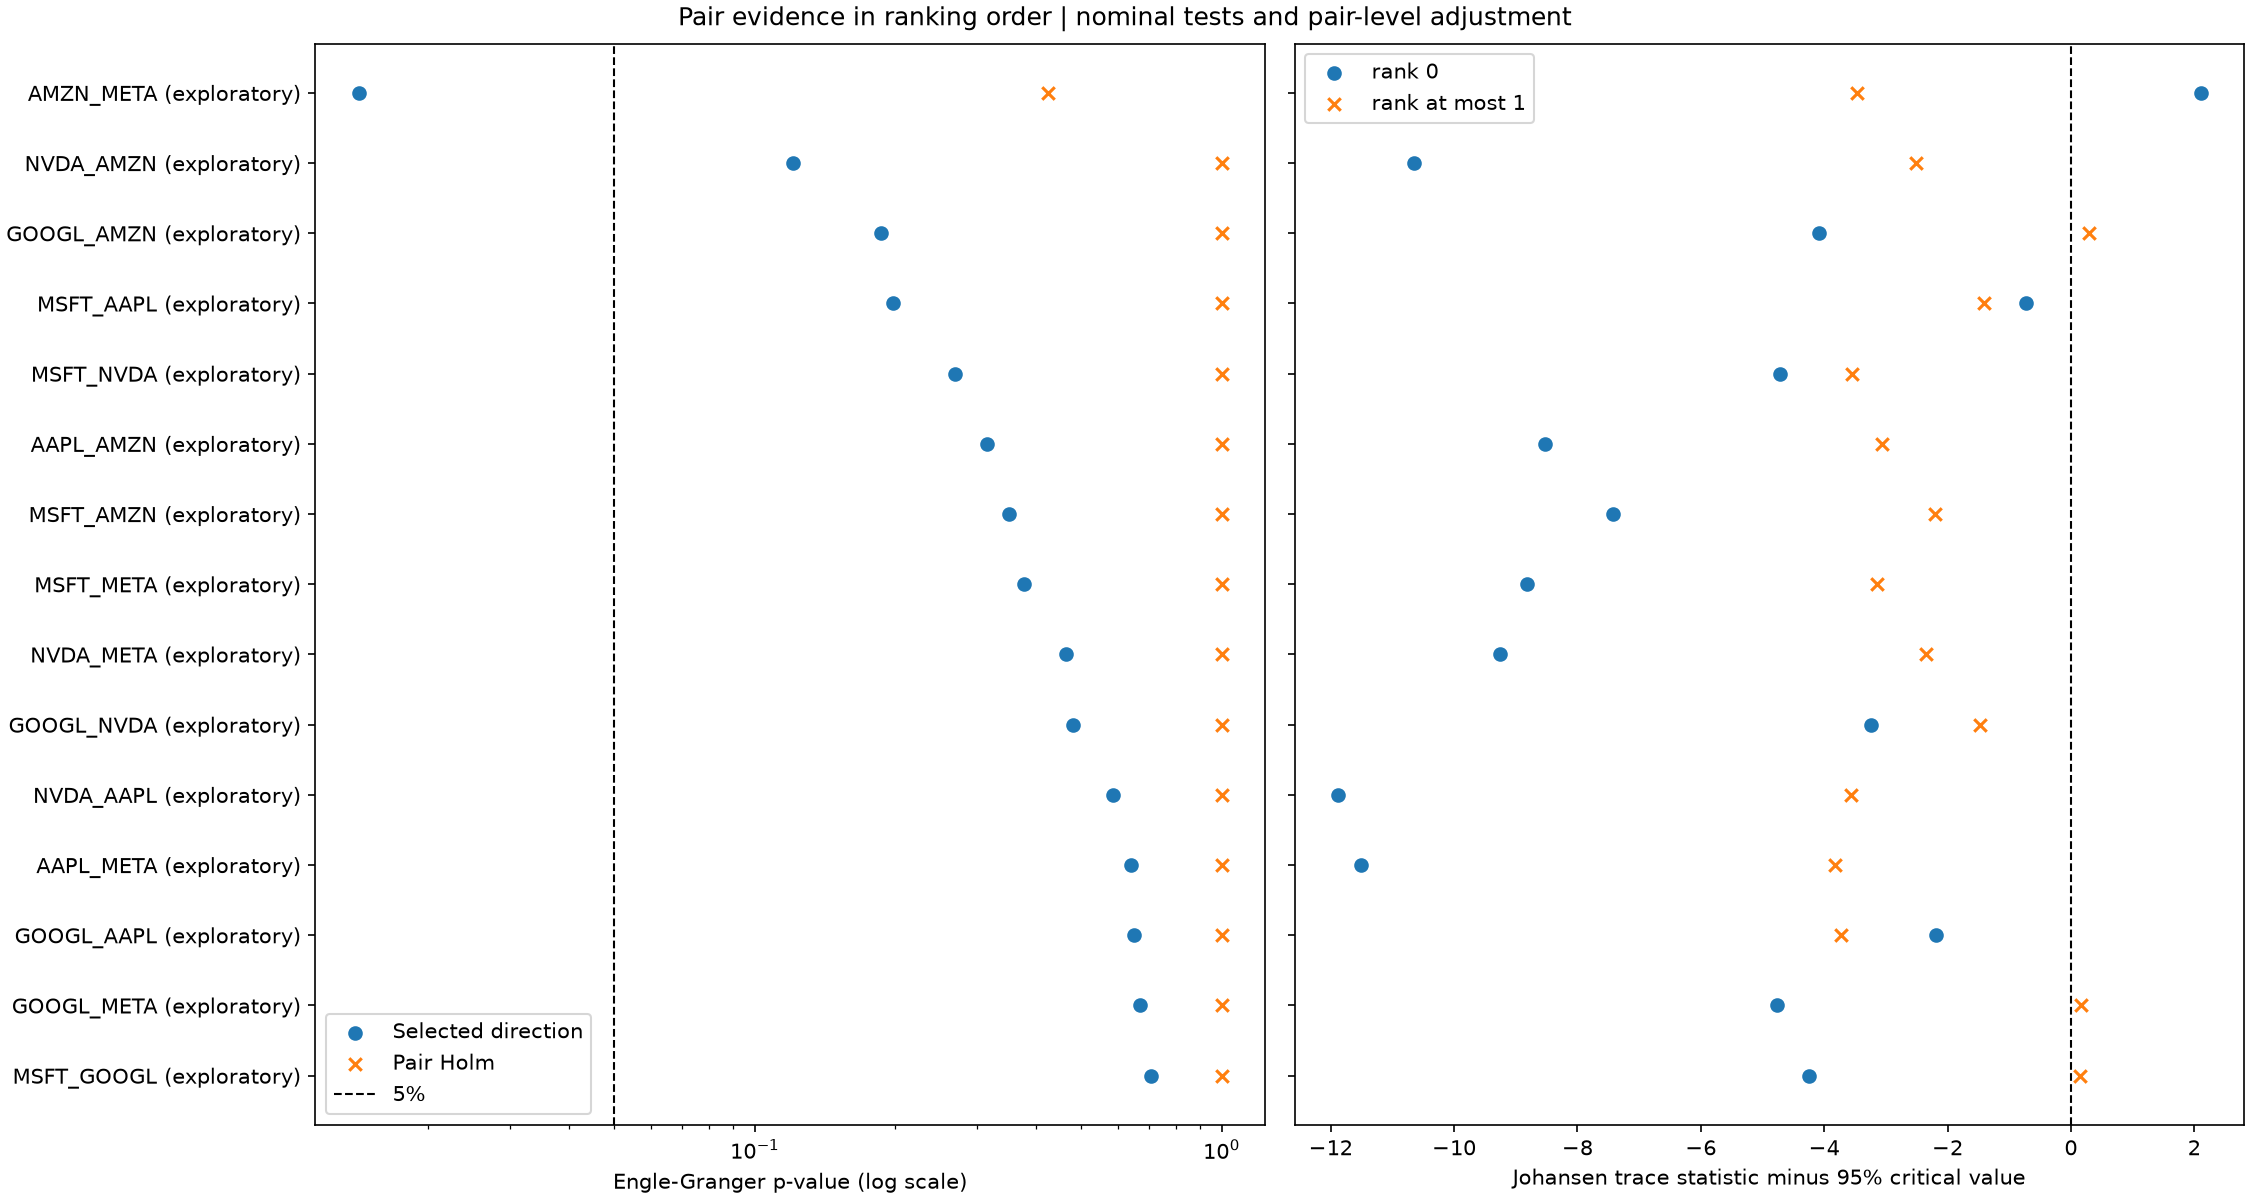

In [3]:
display(tables["johansen_tests"][["pair_id", "levels_lag", "k_ar_diff", "trace_rank_95", "max_eig_rank_95"]])
display(tables["pair_ranking"][["rank", "pair_id", "dependent", "independent", "eg_pvalue", "eg_pair_pvalue", "holm_pair_pvalue", "method_agreement", "evidence_label"]])
display(Image(filename=str(root / "outputs/figures/pair_selection/method_comparison.png")))

## Shortlist and historical diagnostics

AMZN_META is the only pair supported by both nominal tests. Its selected direction is AMZN on META, with Engle-Granger p=0.01419, but its Holm-adjusted pair p-value is 0.42580. No pair meets the adopted support conditions. AMZN_META and the next-ranked pair, NVDA_AMZN (AMZN on NVDA), therefore continue as exploratory candidates.

Half-life is an in-sample AR(1) approximation. Regressions in 2018-2021 and 2022-2025 show how much the selected-direction hedge ratio changes. Neither diagnostic changes the ranking or demonstrates a profitable trade.

,pair_id,spread_column,intercept,beta,half_life_sessions,beta_change_abs,reason
0,AMZN_META,AMZN_on_META,1.517679,0.599428,77.532052,0.576635,Rank 1: both method agreement; EG p=0.0141932;...
1,NVDA_AMZN,AMZN_on_NVDA,4.152697,0.239636,104.079286,0.178181,Rank 2: neither method agreement; EG p=0.12107...


,pair_id,period,dependent,independent,fit_start,fit_end,nobs,intercept,beta,r_squared
0,MSFT_GOOGL,2018_2021,MSFT,GOOGL,2018-01-02,2021-12-31,1008,0.213139,1.132119,0.871211
1,MSFT_GOOGL,2022_2025,MSFT,GOOGL,2022-01-03,2025-12-31,1003,2.104946,0.757332,0.822315
2,MSFT_NVDA,2018_2021,MSFT,NVDA,2018-01-02,2021-12-31,1008,3.868167,0.581175,0.788173
3,MSFT_NVDA,2022_2025,MSFT,NVDA,2022-01-03,2025-12-31,1003,4.808694,0.265234,0.945722
4,MSFT_AAPL,2018_2021,MSFT,AAPL,2018-01-02,2021-12-31,1008,1.575371,0.813380,0.945221
5,MSFT_AAPL,2022_2025,MSFT,AAPL,2022-01-03,2025-12-31,1003,-0.117183,1.144253,0.797494
6,MSFT_AMZN,2018_2021,AMZN,MSFT,2018-01-02,2021-12-31,1008,0.859959,0.759319,0.902158
7,MSFT_AMZN,2022_2025,AMZN,MSFT,2022-01-03,2025-12-31,1003,-1.412090,1.099656,0.847295
8,MSFT_META,2018_2021,MSFT,META,2018-01-02,2021-12-31,1008,-1.966510,1.309377,0.843682
9,MSFT_META,2022_2025,MSFT,META,2022-01-03,2025-12-31,1003,3.504835,0.405258,0.939637


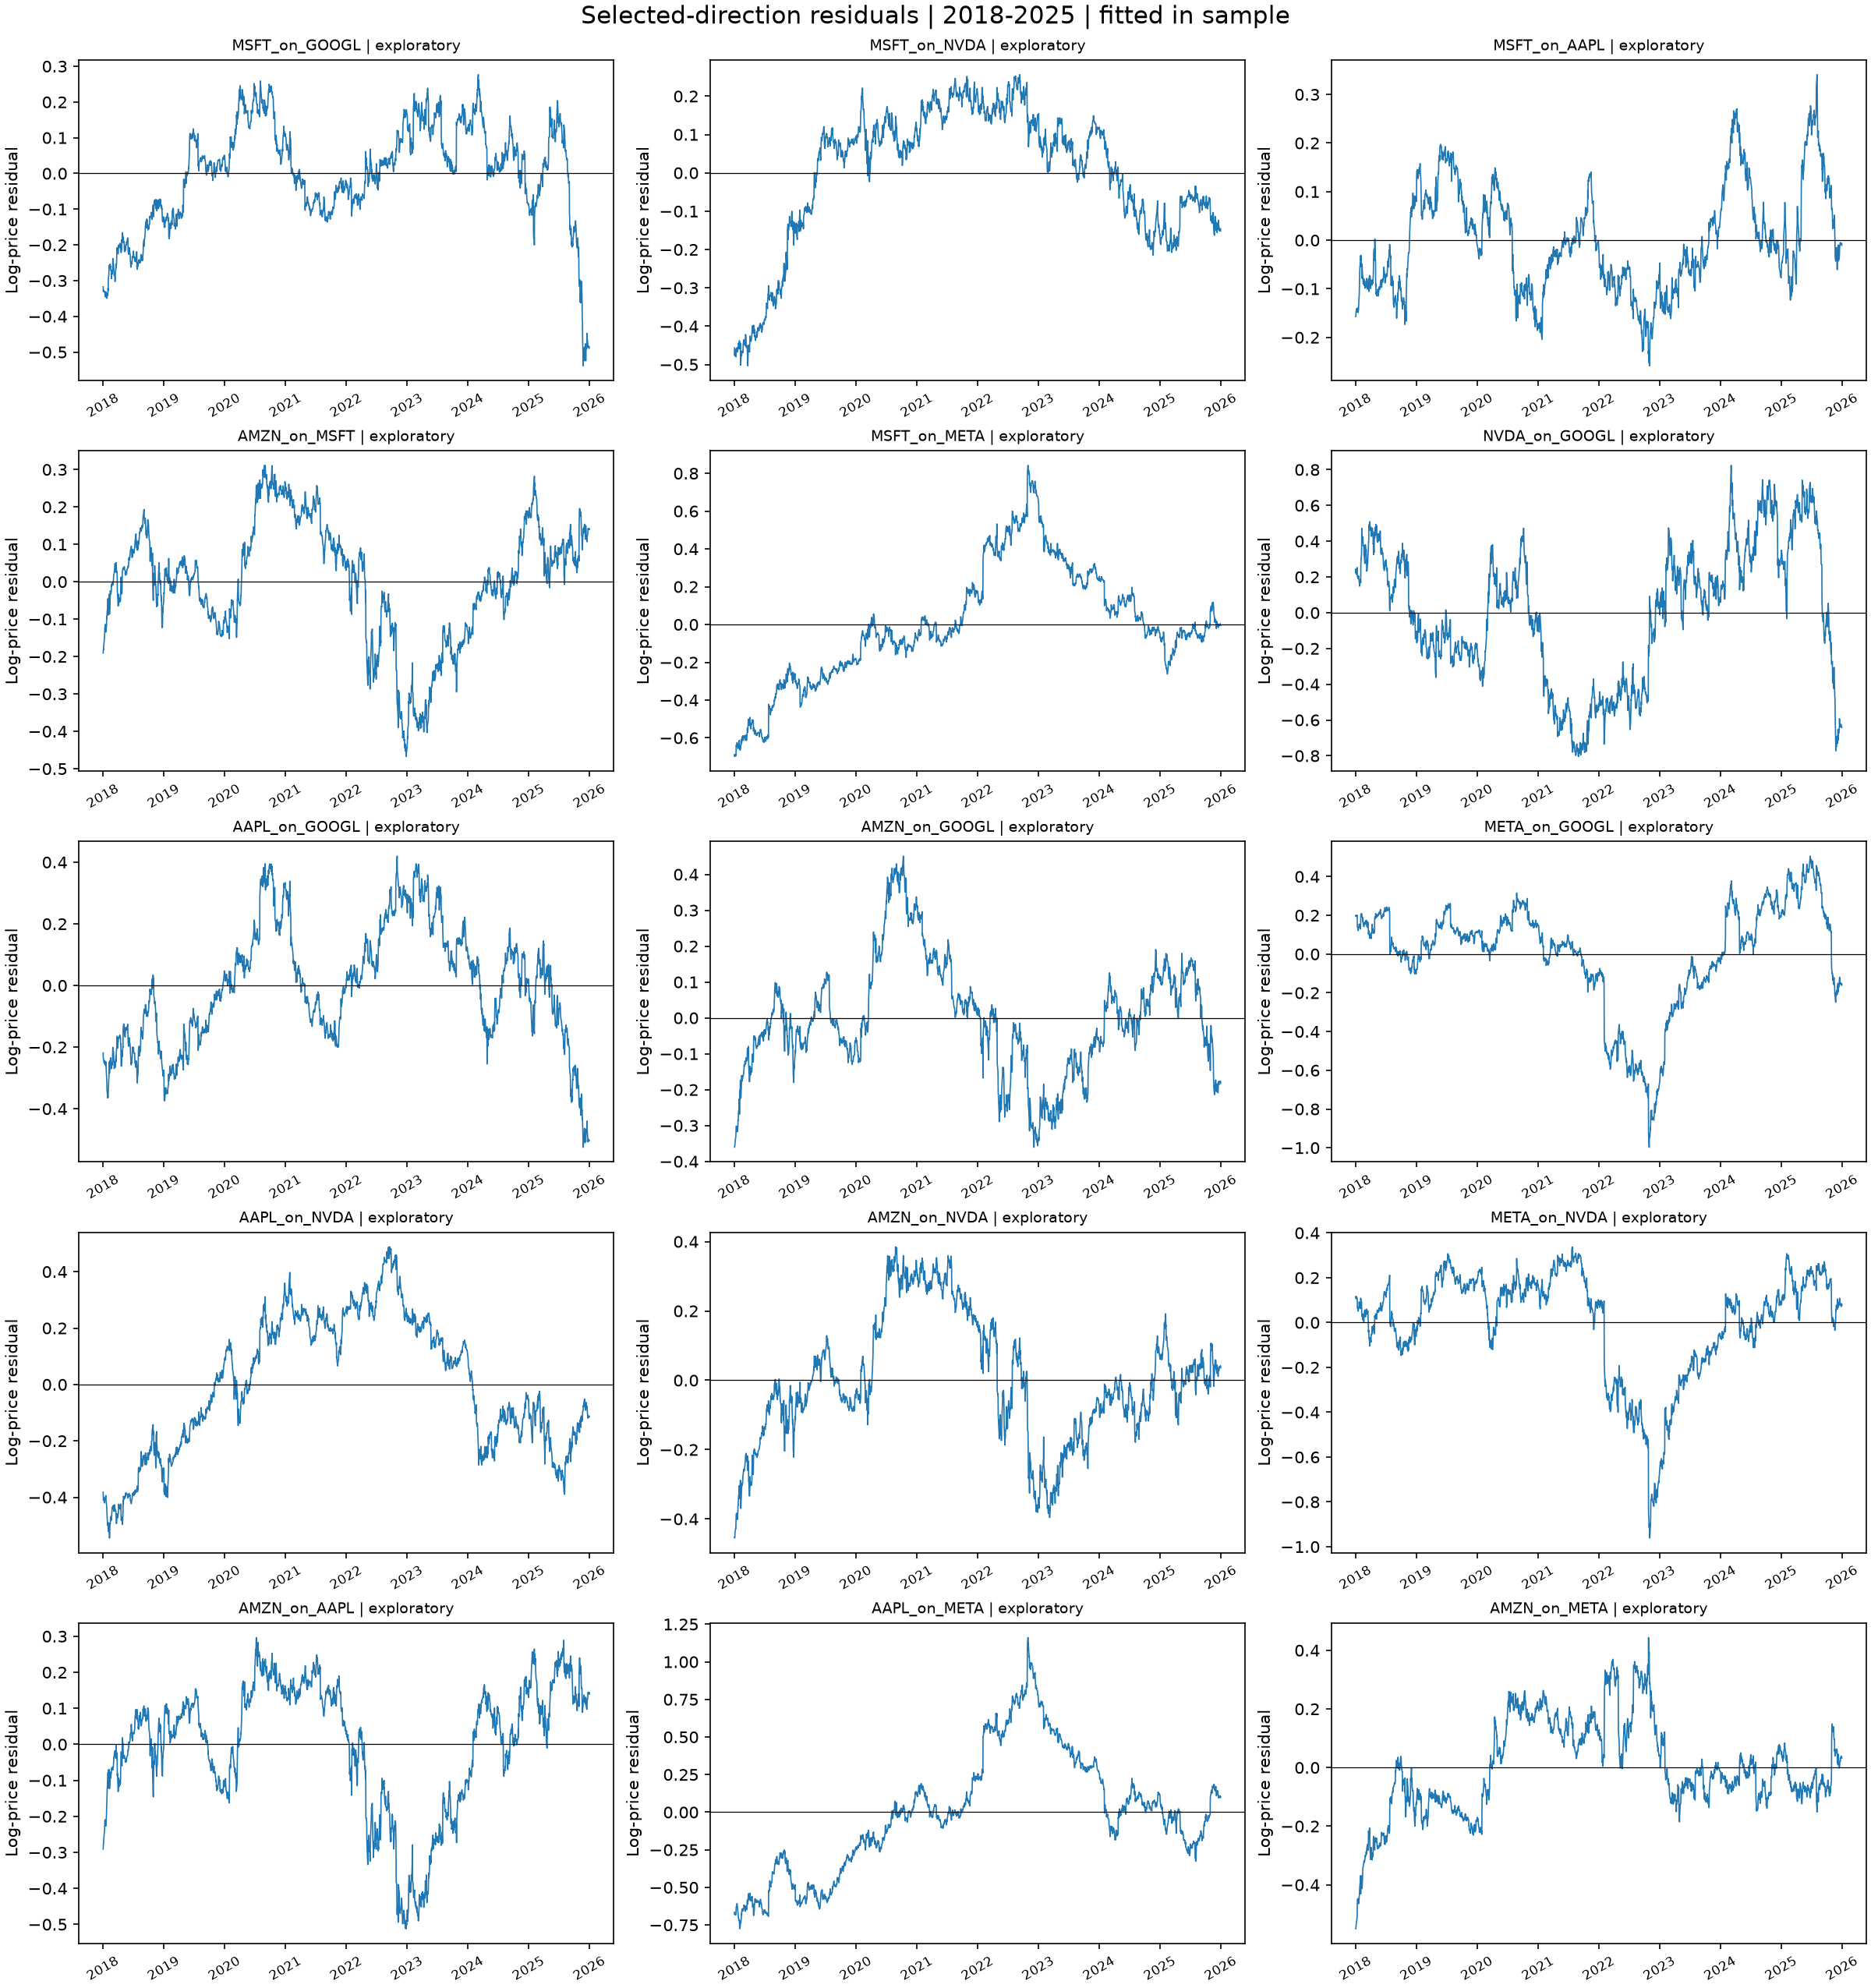

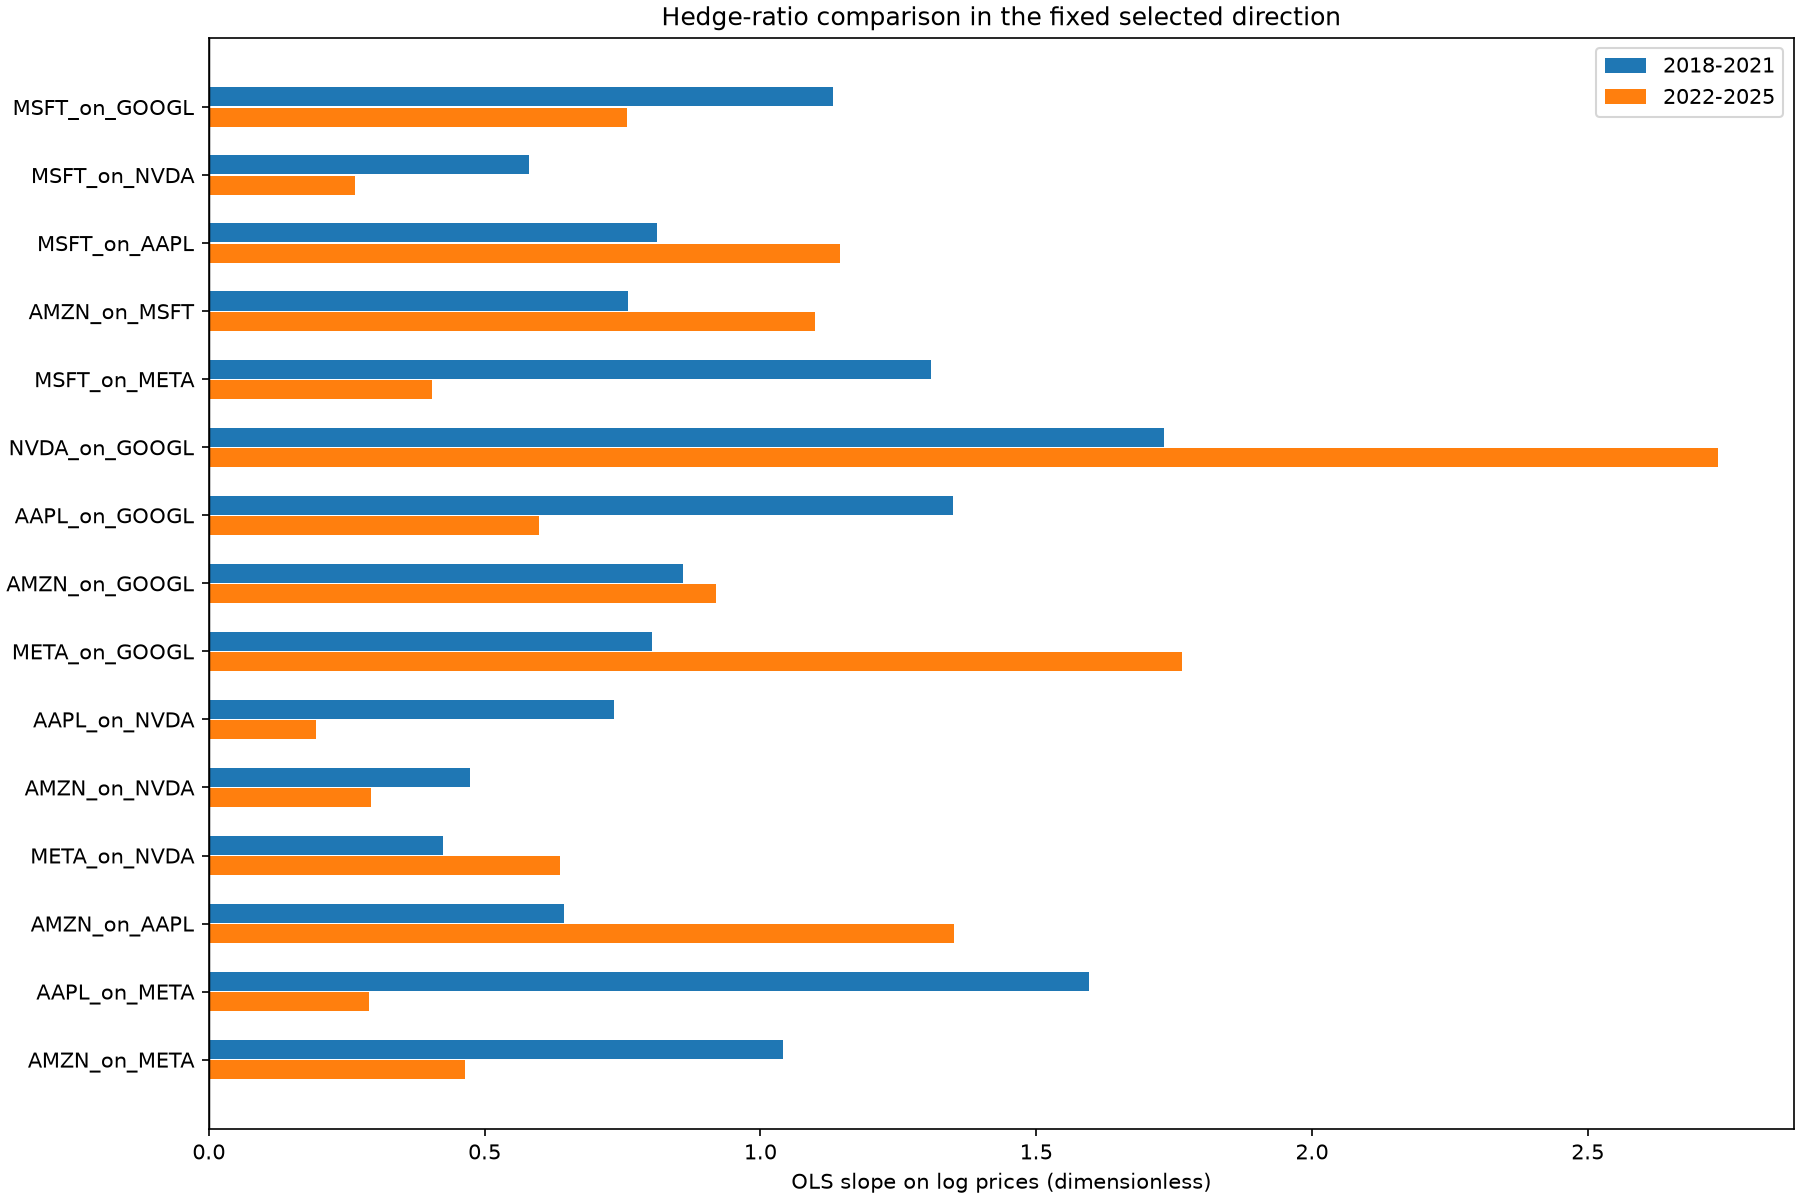

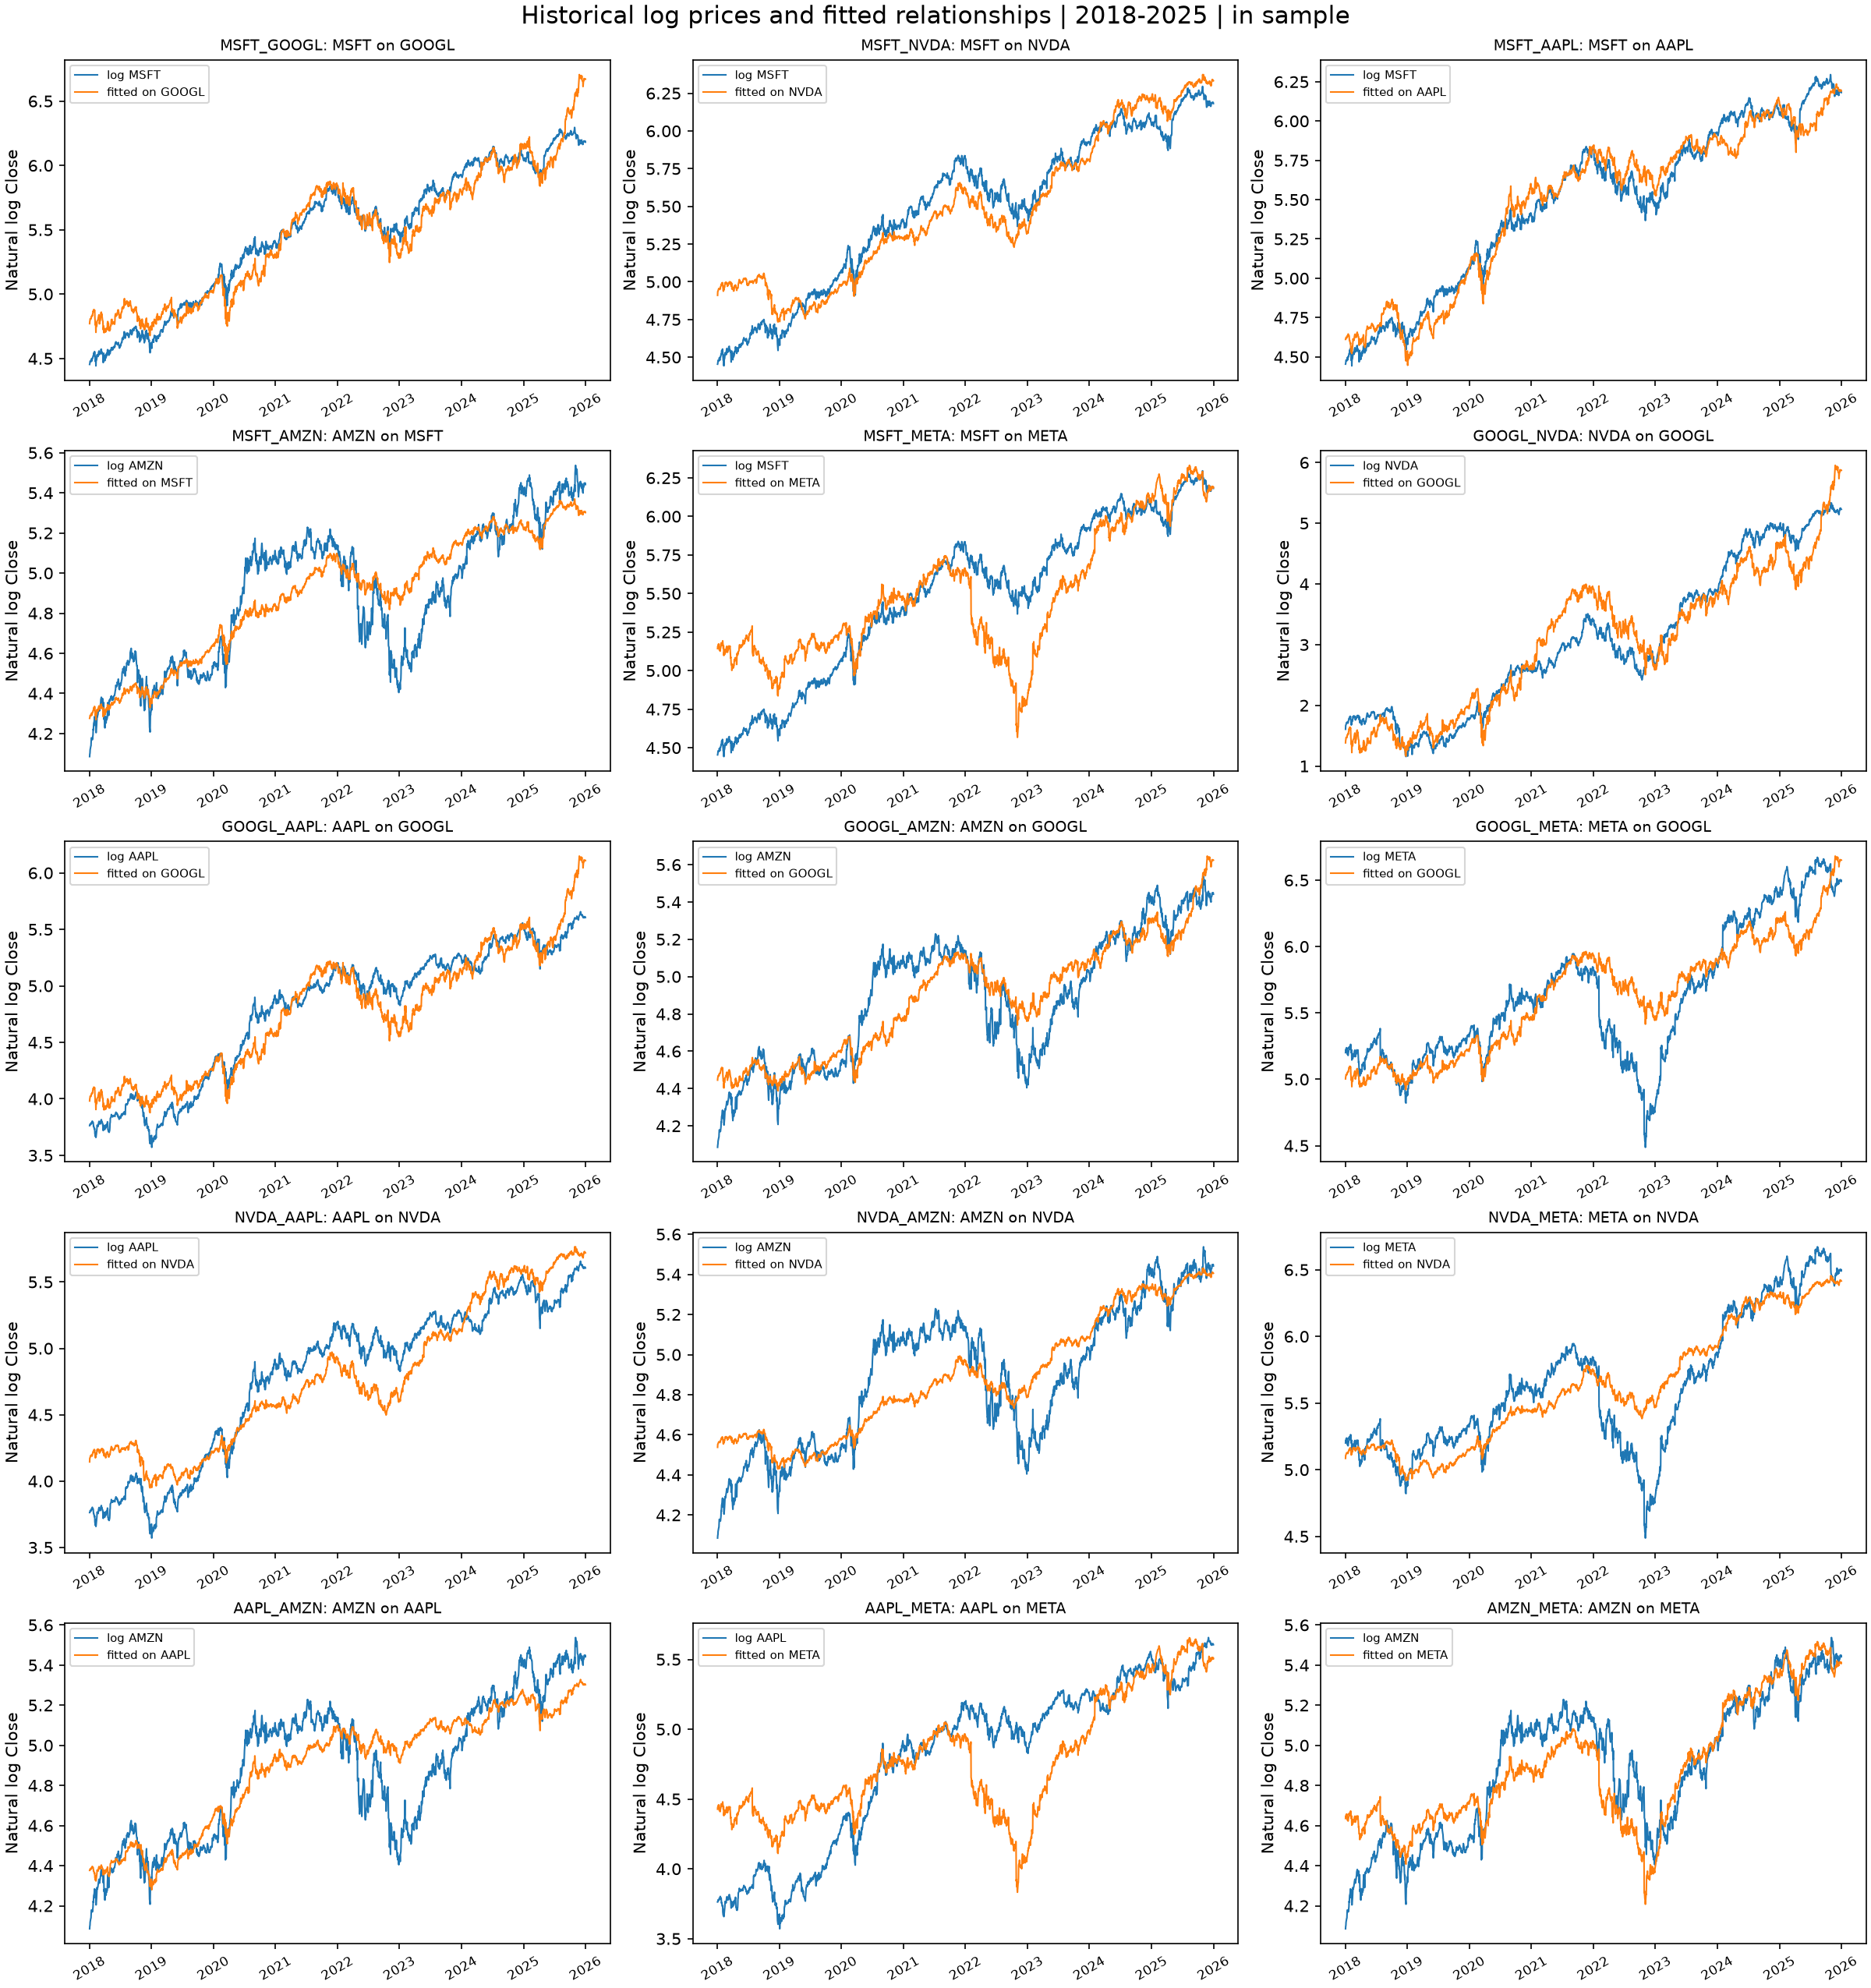

In [4]:
display(tables["shortlist"][["pair_id", "spread_column", "intercept", "beta", "half_life_sessions", "beta_change_abs", "reason"]])
display(tables["hedge_stability"])
display(Image(filename=str(root / "outputs/figures/pair_selection/residual_histories.png")))
display(Image(filename=str(root / "outputs/figures/pair_selection/hedge_stability.png")))
display(Image(filename=str(root / "outputs/figures/pair_selection/pair_fits.png")))

## Reproduction and the next phase

Every output hash is checked below, and reloaded parameters recreate each saved historical spread. These are in-sample residuals. Phase 4 will use the full-history coefficients and estimate normalization on 2025 residuals only. Phase 5 must refit the regression on 2018-2023 for 2024-2025 model validation; that validation remains conditional on a shortlist chosen through 2025.

The run metadata records real-eigenvalue casting warnings from statsmodels: the imaginary parts are exactly zero. A nonzero imaginary part, collinearity warning, failed fit, or non-finite statistic stops the run. No specification was varied after seeing the results.

In [5]:
for relative, expected in metadata["outputs"].items():
    assert sha256(root / relative) == expected, relative
prices = pd.read_csv(root / metadata["input"]["file"], usecols=["Date"] + [f"{symbol}_Close" for symbol in metadata["settings"]["values"]["stocks"]], parse_dates=["Date"]).set_index("Date")
spreads = pd.read_csv(root / "data/processed/pair_spreads_historical.csv", parse_dates=["Date"]).set_index("Date")
artifacts = [name for name in metadata["outputs"] if name.endswith(".json")]
for relative in artifacts:
    parameters = json.loads((root / relative).read_text())
    np.testing.assert_allclose(reconstruct_spread(prices, parameters), spreads[parameters["spread_column"]], rtol=1e-7, atol=1e-9)
print(f"Verified {len(metadata['outputs'])} output hashes and reconstructed {len(artifacts)} spreads.")
display(pd.DataFrame(metadata["leakage_audit"]))

Verified 24 output hashes and reconstructed 15 spreads.


,object,fit_window,applied_to,verdict
0,integration and lag choices,"[2018-01-02, 2025-12-31]",historical test specifications,historical only
1,pair and direction selection,"[2018-01-02, 2025-12-31]",shortlist for later evaluation,no 2026 input; later LSTM validation is condit...
2,full-history OLS coefficients,"[2018-01-02, 2025-12-31]",in-sample residuals and the future Phase 4 han...,in-sample residuals are not out-of-sample evid...
3,hedge stability fits,"[{'period': '2018_2021', 'fit_start': '2018-01...",historical diagnostics only,does not change fitted trading coefficients
